In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# 1. Reproducibility & Device
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 2. Transforms (Normalize RGB channels using standard CIFAR-10 mean & std)
transform = transforms.Compose([
transforms.ToTensor(),
transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

# 3. Load CIFAR-10 Train (50,000) & Test (10,000)
full_train_dataset = datasets.CIFAR10(
root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.CIFAR10(
root="./data", train=False, download=True, transform=transform
)

# 4. Split full training set (50,000) -> Train (40,000) + Validation (10,000)
train_size = 40000
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# 5. DataLoaders
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# 6. Quick sanity check
images, labels = next(iter(train_loader))
print(f"Train samples: {len(train_dataset)} | Val samples: {len(val_dataset)} | Test samples: {len(test_dataset)}")
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Classes:", full_train_dataset.classes)

Using device: cpu


100%|██████████| 170M/170M [10:04<00:00, 282kB/s]    


Train samples: 40000 | Val samples: 10000 | Test samples: 10000
Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Using device: cpu
Trainable parameters: 1,707,274
Epoch [01/10] Train Loss: 1.6768, Train Acc: 40.62% | Val Loss: 1.5482, Val Acc: 45.43%
Epoch [02/10] Train Loss: 1.4578, Train Acc: 48.89% | Val Loss: 1.4328, Val Acc: 49.01%
Epoch [03/10] Train Loss: 1.3304, Train Acc: 53.23% | Val Loss: 1.4332, Val Acc: 49.94%
Epoch [04/10] Train Loss: 1.2295, Train Acc: 56.88% | Val Loss: 1.3756, Val Acc: 52.14%
Epoch [05/10] Train Loss: 1.1397, Train Acc: 59.60% | Val Loss: 1.4034, Val Acc: 52.23%
Epoch [06/10] Train Loss: 1.0643, Train Acc: 62.54% | Val Loss: 1.3943, Val Acc: 53.06%
Epoch [07/10] Train Loss: 0.9771, Train Acc: 65.60% | Val Loss: 1.4121, Val Acc: 53.23%
Epoch [08/10] Train Loss: 0.8973, Train Acc: 68.30% | Val Loss: 1.4511, Val Acc: 53.59%
Epoch [09/10] Train Loss: 0.8203, Train Acc: 71.10% | Val Loss: 1.4672, Val Acc: 54.58%
Epoch [10/10] Train Loss: 0.7521, Train Acc: 73.63% | Val Loss: 1.5606, Val Acc: 52.63%
Final Train Accuracy: 73.63%
Final Validation Accuracy: 52.63%
Final T

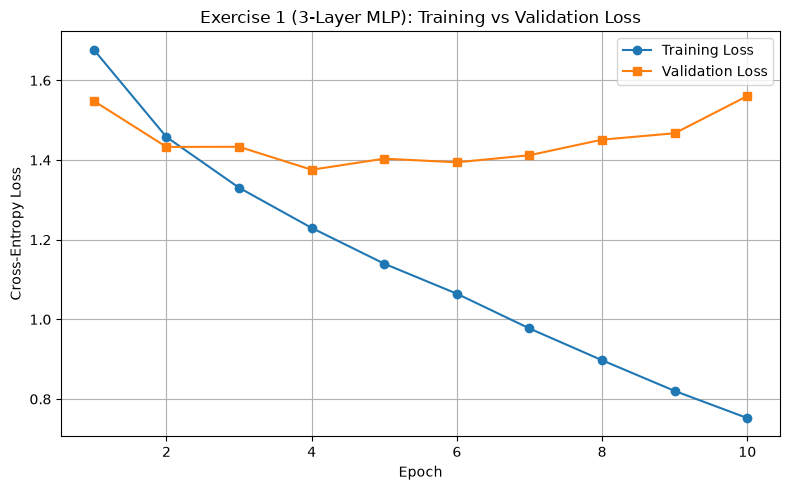

In [4]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "2"

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

full_train_dataset = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [40000, 10000],
    generator=torch.Generator().manual_seed(42),
)

batch_size = 256
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# 3-Layer MLP classifier (3072 -> 512 -> 256 -> 10)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3 * 32 * 32, 512),
    nn.ReLU(),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 10),
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")

epochs = 10
train_losses, val_losses, train_accs, val_accs = [], [], [], []

for epoch in range(1, epochs + 1):
    model.train()
    tr_loss, tr_ok, tr_n = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        tr_loss += float(loss.item()) * x.size(0)
        tr_ok += int((out.argmax(1) == y).sum().item())
        tr_n += int(y.size(0))

    train_losses.append(float(tr_loss / tr_n))
    train_accs.append(float(100.0 * tr_ok / tr_n))

    model.eval()
    va_loss, va_ok, va_n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            va_loss += float(loss.item()) * x.size(0)
            va_ok += int((out.argmax(1) == y).sum().item())
            va_n += int(y.size(0))

    val_losses.append(float(va_loss / va_n))
    val_accs.append(float(100.0 * va_ok / va_n))

    print(
        f"Epoch [{epoch:02d}/{epochs:02d}] "
        f"Train Loss: {train_losses[-1]:.4f}, Train Acc: {train_accs[-1]:.2f}% | "
        f"Val Loss: {val_losses[-1]:.4f}, Val Acc: {val_accs[-1]:.2f}%"
    )

model.eval()
te_ok, te_n = 0, 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        te_ok += int((model(x).argmax(1) == y).sum().item())
        te_n += int(y.size(0))

test_acc = 100.0 * te_ok / te_n
print(f"Final Train Accuracy: {train_accs[-1]:.2f}%")
print(f"Final Validation Accuracy: {val_accs[-1]:.2f}%")
print(f"Final Test Accuracy: {test_acc:.2f}%")

tr_arr = np.asarray(train_losses, dtype=float).ravel()
va_arr = np.asarray(val_losses, dtype=float).ravel()
n_pts = min(len(tr_arr), len(va_arr))

if n_pts > 1:
    ep = np.arange(1, n_pts + 1)
    plt.figure(figsize=(8, 5))
    plt.plot(ep, tr_arr[:n_pts], marker="o", label="Training Loss")
    plt.plot(ep, va_arr[:n_pts], marker="s", label="Validation Loss")
    plt.title("Exercise 1 (3-Layer MLP): Training vs Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("exercise1_mlp_loss.png", dpi=150)
    plt.show()
else:
    print("Loss arrays:", tr_arr, va_arr)

In [3]:
import matplotlib.pyplot as plt
import torch

model.eval()
te_ok, te_n = 0, 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        te_ok += (model(x).argmax(1) == y).sum().item()
        te_n += y.size(0)

test_acc = 100.0 * te_ok / te_n
print(f"Final Train Accuracy: {train_accs[-1]:.2f}%")
print(f"Final Validation Accuracy: {val_accs[-1]:.2f}%")
print(f"Final Test Accuracy: {test_acc:.2f}%")

tr_vals = [float(v) for v in train_losses]
va_vals = [float(v) for v in val_losses]
n_ep = min(len(tr_vals), len(va_vals))

if n_ep > 1:
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, n_ep + 1), tr_vals[:n_ep], marker="o", label="Training Loss")
    plt.plot(range(1, n_ep + 1), va_vals[:n_ep], marker="s", label="Validation Loss")
    plt.title("Exercise 1 (3-Layer MLP): Training vs Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("exercise1_loss.png", dpi=150)
    plt.show()
else:
    print("Loss list values:", tr_vals, va_vals)

Final Train Accuracy: 73.81%
Final Validation Accuracy: 53.45%
Final Test Accuracy: 52.64%
Loss list values: [0.7424229777336121] [1.5630432027816772]


In [5]:
import sys
!{sys.executable} -m pip install torch torchvision matplotlib

  Using cached torch-2.15.0-cp314-cp314-win_amd64.whl.metadata (36 kB)
  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
Using cached torch-2.15.0-cp314-cp314-win_amd64.whl (126.7 MB)
Using cached torchvision-0.29.2-py3-none-win_amd64.whl (1.4 MB)

   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [5]:
class MLPClassifier(nn.Module):
    def __init__(self, input_dim=3 * 32 * 32, hidden1=512, hidden2=256, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, num_classes),
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.net(x)


model = MLPClassifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")

epochs = 15
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(1, epochs + 1):
    model.train()
    running_train_loss, correct_train, total_train = 0.0, 0, 0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * inputs.size(0)
        preds = outputs.argmax(dim=1)
        correct_train += (preds == targets).sum().item()
        total_train += targets.size(0)

    train_loss = running_train_loss / total_train
    train_acc = 100.0 * correct_train / total_train

    model.eval()
    running_val_loss, correct_val, total_val = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_val_loss += loss.item() * inputs.size(0)
            preds = outputs.argmax(dim=1)
            correct_val += (preds == targets).sum().item()
            total_val += targets.size(0)

    val_loss = running_val_loss / total_val
    val_acc = 100.0 * correct_val / total_val

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(
        f"Epoch [{epoch:02d}/{epochs:02d}] "
        f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%"
    )

Trainable parameters: 1,707,274
Epoch [01/15] Train Loss: 1.6752, Train Acc: 40.59% | Val Loss: 1.5641, Val Acc: 44.33%
Epoch [02/15] Train Loss: 1.4577, Train Acc: 48.54% | Val Loss: 1.4589, Val Acc: 48.35%
Epoch [03/15] Train Loss: 1.3409, Train Acc: 52.56% | Val Loss: 1.4227, Val Acc: 50.21%
Epoch [04/15] Train Loss: 1.2512, Train Acc: 55.98% | Val Loss: 1.3974, Val Acc: 51.97%
Epoch [05/15] Train Loss: 1.1624, Train Acc: 58.91% | Val Loss: 1.4217, Val Acc: 51.33%
Epoch [06/15] Train Loss: 1.0877, Train Acc: 61.43% | Val Loss: 1.3996, Val Acc: 52.32%
Epoch [07/15] Train Loss: 1.0075, Train Acc: 64.45% | Val Loss: 1.4396, Val Acc: 51.71%
Epoch [08/15] Train Loss: 0.9400, Train Acc: 66.73% | Val Loss: 1.4882, Val Acc: 52.00%
Epoch [09/15] Train Loss: 0.8562, Train Acc: 69.57% | Val Loss: 1.5329, Val Acc: 51.97%
Epoch [10/15] Train Loss: 0.7902, Train Acc: 71.93% | Val Loss: 1.5713, Val Acc: 52.08%
Epoch [11/15] Train Loss: 0.7223, Train Acc: 74.29% | Val Loss: 1.6672, Val Acc: 52.05%


In [6]:
# 1. Plot Training vs Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses, marker="o", label="Training Loss")
plt.plot(range(1, epochs + 1), val_losses, marker="s", label="Validation Loss")
plt.title("Exercise 1 (3-Layer MLP): Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. Evaluate on held-out Test Set (10,000 images)
model.eval()
correct_test, total_test = 0, 0
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1)
        correct_test += (preds == targets).sum().item()
    total_test += targets.size(0)
test_acc = 100.0 * correct_test / total_test
print(f"Final Train Accuracy: {train_accs[-1]:.2f}%")
print(f"Final Validation Accuracy: {val_accs[-1]:.2f}%")
print(f"Final Test Accuracy: {test_acc:.2f}%")

: 